<a href="https://colab.research.google.com/github/jplordelo92-rgb/AULA-COMPUTATIONAL-INTELLIGENCE-/blob/jplordelo92-rgb-patch-1/ProjetoTech.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import random
import time
import networkx as nx

# ==========================================
# 1. ARQUITETURA: PADRÃO OBSERVER E SIMULADOR
# ==========================================
class ObservadorRoteamento:
    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        pass

class SimuladorRede:
    def __init__(self):
        self.grafo = nx.Graph()
        self.motores = []

    def adicionar_motor(self, motor):
        self.motores.append(motor)

    def notificar_motores(self, origem, destino, tipo_evento):
        for motor in self.motores:
            motor.reagir_mudanca_rede(origem, destino, tipo_evento)

    def adicionar_enlace(self, no_a, no_b, latencia, zona_proibida=False):
        self.grafo.add_edge(no_a, no_b, latencia=latencia, zona_proibida=zona_proibida)
        self.grafo[no_a][no_b]['feromonio'] = 1.0

    def derrubar_enlace(self, no_a, no_b):
        if self.grafo.has_edge(no_a, no_b):
            self.grafo.remove_edge(no_a, no_b)
            print(f"\n[SIMULADOR] ALERTA: Enlace {no_a}-{no_b} cortado!")
            self.notificar_motores(no_a, no_b, "FALHA_ENLACE")

# ==========================================
# 2. MOTOR ACO (INTELIGÊNCIA COMPUTACIONAL)
# ==========================================
class MotorACO(ObservadorRoteamento):
    def __init__(self, grafo_referencia, num_formigas=10, taxa_evaporacao=0.15, alfa=1.0, beta=2.0):
        self.grafo = grafo_referencia
        self.num_formigas = num_formigas
        self.taxa_evaporacao = taxa_evaporacao
        self.alfa = alfa
        self.beta = beta

    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        pass # O ACO adapta-se naturalmente pela falta do enlace na próxima iteração

    def escolher_proximo_no(self, no_atual, visitados):
        vizinhos = list(self.grafo.neighbors(no_atual))
        vizinhos_validos = []

        # Filtra os nós visitados e as zonas proibidas
        for v in vizinhos:
            enlace = self.grafo[no_atual][v]
            if v not in visitados and not enlace.get('zona_proibida', False):
                vizinhos_validos.append(v)

        if not vizinhos_validos:
            return None

        probabilidades = []
        soma_total = 0

        for vizinho in vizinhos_validos:
            feromonio = self.grafo[no_atual][vizinho].get('feromonio', 1.0)
            latencia = self.grafo[no_atual][vizinho].get('latencia', 1)
            heuristica = 1.0 / latencia

            score = (feromonio ** self.alfa) * (heuristica ** self.beta)
            probabilidades.append(score)
            soma_total += score

        probabilidades = [p / soma_total for p in probabilidades]
        return random.choices(vizinhos_validos, weights=probabilidades, k=1)[0]

    def simular_formiga(self, origem, destino):
        caminho = [origem]
        no_atual = origem
        custo_total = 0

        while no_atual != destino:
            proximo_no = self.escolher_proximo_no(no_atual, caminho)
            if proximo_no is None:
                return None, 0

            custo_total += self.grafo[no_atual][proximo_no].get('latencia', 1)
            caminho.append(proximo_no)
            no_atual = proximo_no

        return caminho, custo_total

    def atualizar_feromonios(self, caminhos_das_formigas):
        for u, v in self.grafo.edges():
            self.grafo[u][v]['feromonio'] *= (1.0 - self.taxa_evaporacao)

        for caminho, custo in caminhos_das_formigas:
            reforco = 100.0 / custo
            for i in range(len(caminho) - 1):
                u, v = caminho[i], caminho[i+1]
                self.grafo[u][v]['feromonio'] += reforco

    def executar_iteracao(self, origem, destino):
        caminhos = []
        melhor_caminho = None
        menor_custo = float('inf')

        for _ in range(self.num_formigas):
            caminho, custo = self.simular_formiga(origem, destino)
            if caminho:
                caminhos.append((caminho, custo))
                if custo < menor_custo:
                    menor_custo = custo
                    melhor_caminho = caminho

        if caminhos:
            self.atualizar_feromonios(caminhos)

        return melhor_caminho, menor_custo

# ==========================================
# 3. BASELINE OBRIGATÓRIO: MOTOR DIJKSTRA
# ==========================================
class MotorDijkstra(ObservadorRoteamento):
    def __init__(self, grafo_referencia):
        self.grafo = grafo_referencia
        self.rota_em_cache = None
        self.custo_em_cache = float('inf')

    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        if tipo_evento == "FALHA_ENLACE":
            print("[MOTOR DIJKSTRA] Rota invalidada. Forçando recálculo...")
            self.rota_em_cache = None

    def obter_subgrafo_seguro(self):
        # O Dijkstra estático também precisa ignorar as zonas proibidas
        arestas_validas = [
            (u, v) for u, v, d in self.grafo.edges(data=True)
            if not d.get('zona_proibida', False)
        ]
        return self.grafo.edge_subgraph(arestas_validas)

    def executar_iteracao(self, origem, destino):
        inicio = time.perf_counter()

        if self.rota_em_cache is None:
            subgrafo = self.obter_subgrafo_seguro()
            try:
                self.rota_em_cache = nx.dijkstra_path(subgrafo, origem, destino, weight='latencia')
                self.custo_em_cache = nx.dijkstra_path_length(subgrafo, origem, destino, weight='latencia')
            except nx.NetworkXNoPath:
                self.rota_em_cache = None
                self.custo_em_cache = float('inf')

        tempo = (time.perf_counter() - inicio) * 1000
        return self.rota_em_cache, self.custo_em_cache, tempo

# ==========================================
# 4. CORRIDA COMPARATIVA: ACO vs DIJKSTRA
# ==========================================
simulador = SimuladorRede()
simulador.adicionar_enlace('A', 'B', latencia=10)
simulador.adicionar_enlace('A', 'C', latencia=20)
simulador.adicionar_enlace('B', 'D', latencia=15)
simulador.adicionar_enlace('C', 'D', latencia=5)
simulador.adicionar_enlace('D', 'E', latencia=10)
simulador.adicionar_enlace('B', 'E', latencia=35)
# Rotas marcadas como inseguras para testar o filtro
simulador.adicionar_enlace('A', 'Z', latencia=2, zona_proibida=True)
simulador.adicionar_enlace('Z', 'E', latencia=2, zona_proibida=True)

motor_aco = MotorACO(simulador.grafo)
motor_dijkstra = MotorDijkstra(simulador.grafo)

simulador.adicionar_motor(motor_aco)
simulador.adicionar_motor(motor_dijkstra)

print("=== INÍCIO DA COMPARAÇÃO ===\n")

for iteracao in range(1, 8):
    print(f"--- ITERAÇÃO {iteracao} ---")

    if iteracao == 4:
        simulador.derrubar_enlace('C', 'D')

    rota_dijk, custo_dijk, tempo_dijk = motor_dijkstra.executar_iteracao('A', 'E')
    print(f"[DIJKSTRA] Rota: {rota_dijk} | Latência: {custo_dijk}ms | CPU: {tempo_dijk:.4f}ms")

    inicio_aco = time.perf_counter()
    rota_aco, custo_aco = motor_aco.executar_iteracao('A', 'E')
    tempo_aco = (time.perf_counter() - inicio_aco) * 1000
    print(f"[ACO]      Rota: {rota_aco} | Latência: {custo_aco}ms | CPU: {tempo_aco:.4f}ms\n")

=== INÍCIO DA COMPARAÇÃO ===

--- ITERAÇÃO 1 ---
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 3.8057ms
[ACO]      Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.5182ms

--- ITERAÇÃO 2 ---
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.0005ms
[ACO]      Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.4277ms

--- ITERAÇÃO 3 ---
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.0003ms
[ACO]      Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.4220ms

--- ITERAÇÃO 4 ---

[SIMULADOR] ALERTA: Enlace C-D cortado!
[MOTOR DIJKSTRA] Rota invalidada. Forçando recálculo...
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 2.2717ms
[ACO]      Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.3284ms

--- ITERAÇÃO 5 ---
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.0003ms
[ACO]      Rota: ['A', 'B', 'D', 'E'] | Latência: 35ms | CPU: 0.3492ms

--- ITERAÇÃO 6 ---
[DIJKSTRA] Rota: ['A', 'B', 'D', 'E'] | Latê

In [3]:
import random
import math

# ==========================================
# 5. OTIMIZADOR PSO (ALOCAÇÃO DE BANDA)
# ==========================================
class Particula:
    def __init__(self, num_fluxos, capacidade_maxima):
        # Cada posição é a quantidade de banda alocada a um fluxo
        # Inicializa com uma divisão conservadora e aleatória
        self.posicao = [random.uniform(1, capacidade_maxima / num_fluxos) for _ in range(num_fluxos)]
        self.velocidade = [random.uniform(-1, 1) for _ in range(num_fluxos)]
        self.pbest_posicao = self.posicao[:]
        self.pbest_fitness = -float('inf')

class MotorPSO:
    def __init__(self, num_particulas, num_fluxos, capacidade_link, iteracoes=50):
        self.num_particulas = num_particulas
        self.num_fluxos = num_fluxos
        self.capacidade = capacidade_link
        self.iteracoes = iteracoes
        self.particulas = [Particula(num_fluxos, capacidade_link) for _ in range(num_particulas)]

        self.gbest_posicao = []
        self.gbest_fitness = -float('inf')

    def calcular_fitness(self, posicao, pesos_prioridade):
        soma_banda = sum(posicao)

        # RESTRIÇÃO: Se exceder a capacidade do enlace, aplicamos uma penalização brutal
        if soma_banda > self.capacidade:
            return - (soma_banda - self.capacidade) * 1000

        # FUNÇÃO OBJETIVO: Maximizar a utilidade agregada.
        # Usamos uma função logarítmica (comum em telecomunicações) onde
        # os fluxos com maior peso (prioridade) "puxam" mais a utilidade para cima.
        utilidade_total = 0
        for i in range(self.num_fluxos):
            banda = max(0.001, posicao[i]) # Evitar erro matemático de log(0)
            utilidade_total += pesos_prioridade[i] * math.log(banda)

        return utilidade_total

    def otimizar(self, pesos_prioridade):
        w = 0.5  # Inércia (tendência a manter a direção atual)
        c1 = 1.5 # Coeficiente Cognitivo (atração para o próprio melhor histórico)
        c2 = 1.5 # Coeficiente Social (atração para o melhor do enxame)

        for iteracao in range(self.iteracoes):
            for p in self.particulas:
                fitness = self.calcular_fitness(p.posicao, pesos_prioridade)

                # Atualiza o melhor pessoal
                if fitness > p.pbest_fitness:
                    p.pbest_fitness = fitness
                    p.pbest_posicao = p.posicao[:]

                # Atualiza o melhor global
                if fitness > self.gbest_fitness:
                    self.gbest_fitness = fitness
                    self.gbest_posicao = p.posicao[:]

            # Move as partículas
            for p in self.particulas:
                for i in range(self.num_fluxos):
                    r1, r2 = random.random(), random.random()

                    # Equação clássica da velocidade do PSO
                    vel = (w * p.velocidade[i] +
                           c1 * r1 * (p.pbest_posicao[i] - p.posicao[i]) +
                           c2 * r2 * (self.gbest_posicao[i] - p.posicao[i]))
                    p.velocidade[i] = vel

                    # Atualiza a posição (garantindo que a banda nunca é negativa)
                    nova_pos = p.posicao[i] + vel
                    p.posicao[i] = max(0.001, nova_pos)

        return self.gbest_posicao, self.gbest_fitness

# ==========================================
# TESTE DO PSO DE ALOCAÇÃO
# ==========================================
print("=== INICIANDO OTIMIZAÇÃO DE BANDA (PSO) ===\n")

# Cenário: O enlace suporta no máximo 100 Mbps.
# Temos 3 fluxos a passar por este enlace.
capacidade_enlace = 100
fluxos = ["Vídeo HD", "Chamada VoIP", "Download Ficheiro"]

# Pesos de prioridade (Quanto maior, mais importante é garantir banda para esse fluxo)
# Ex: Vídeo tem peso 5, VoIP peso 3, Download peso 1.
pesos = [5, 3, 1]

pso = MotorPSO(num_particulas=30, num_fluxos=len(fluxos), capacidade_link=capacidade_enlace, iteracoes=100)
melhor_alocacao, utilidade = pso.otimizar(pesos_prioridade=pesos)

print(f"Capacidade total do enlace: {capacidade_enlace} Mbps")
print("-" * 40)
soma = 0
for i in range(len(fluxos)):
    banda_alocada = melhor_alocacao[i]
    soma += banda_alocada
    print(f"Fluxo '{fluxos[i]}' (Peso {pesos[i]}): {banda_alocada:.2f} Mbps")

print("-" * 40)
print(f"Banda total alocada: {soma:.2f} Mbps")
print(f"Utilidade agregada (Fitness): {utilidade:.4f}")

=== INICIANDO OTIMIZAÇÃO DE BANDA (PSO) ===

Capacidade total do enlace: 100 Mbps
----------------------------------------
Fluxo 'Vídeo HD' (Peso 5): 56.35 Mbps
Fluxo 'Chamada VoIP' (Peso 3): 32.36 Mbps
Fluxo 'Download Ficheiro' (Peso 1): 11.28 Mbps
----------------------------------------
Banda total alocada: 100.00 Mbps
Utilidade agregada (Fitness): 33.0126


A processar a simulação para geração de gráficos...


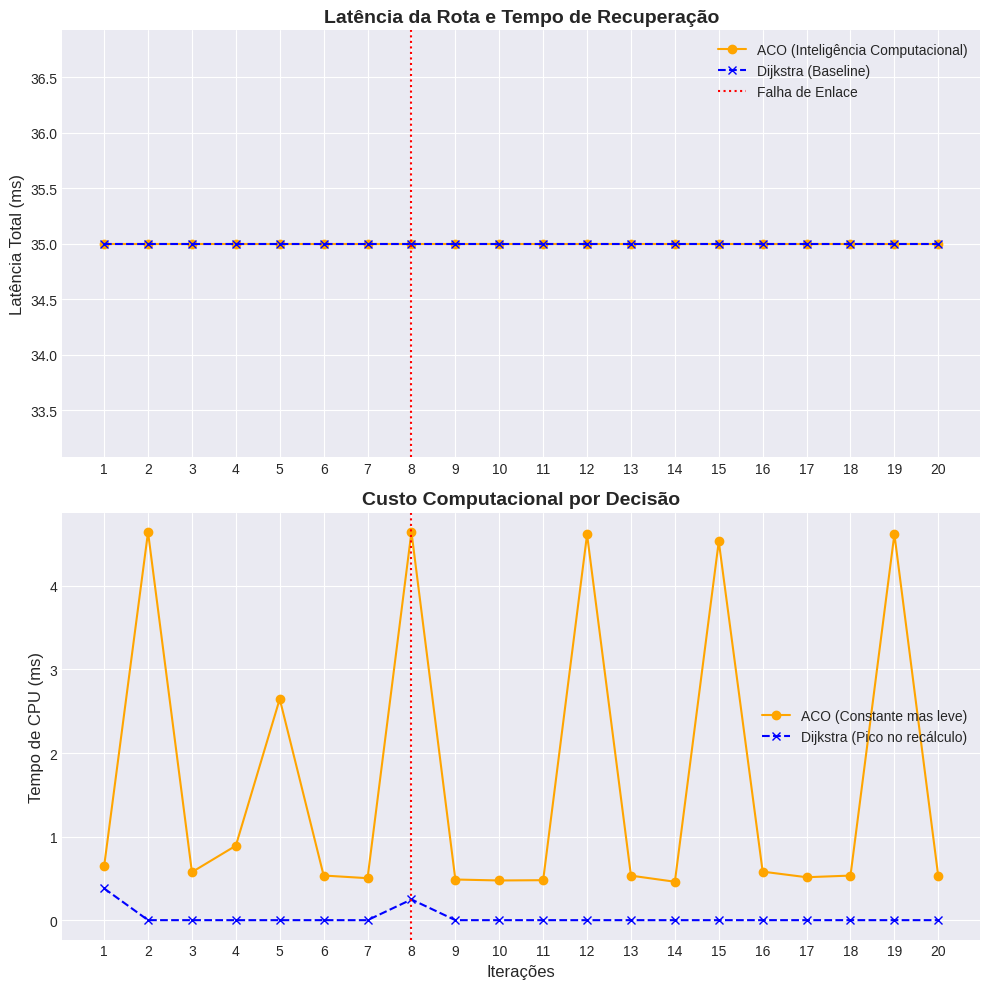

In [5]:
import random
import time
import networkx as nx
import matplotlib.pyplot as plt

# ==========================================
# 1. CLASSES BASE (Simulador e Motores)
# ==========================================
class ObservadorRoteamento:
    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        pass

class SimuladorRede:
    def __init__(self):
        self.grafo = nx.Graph()
        self.motores = []

    def adicionar_motor(self, motor):
        self.motores.append(motor)

    def notificar_motores(self, origem, destino, tipo_evento):
        for motor in self.motores:
            motor.reagir_mudanca_rede(origem, destino, tipo_evento)

    def adicionar_enlace(self, no_a, no_b, latencia, zona_proibida=False):
        self.grafo.add_edge(no_a, no_b, latencia=latencia, zona_proibida=zona_proibida)
        self.grafo[no_a][no_b]['feromonio'] = 1.0

    def derrubar_enlace(self, no_a, no_b):
        if self.grafo.has_edge(no_a, no_b):
            self.grafo.remove_edge(no_a, no_b)
            self.notificar_motores(no_a, no_b, "FALHA_ENLACE")

class MotorACO(ObservadorRoteamento):
    def __init__(self, grafo_referencia, num_formigas=15, taxa_evaporacao=0.2, alfa=1.0, beta=2.0):
        self.grafo = grafo_referencia
        self.num_formigas = num_formigas
        self.taxa_evaporacao = taxa_evaporacao
        self.alfa = alfa
        self.beta = beta

    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        pass

    def escolher_proximo_no(self, no_atual, visitados):
        vizinhos = list(self.grafo.neighbors(no_atual))
        vizinhos_validos = []
        for v in vizinhos:
            enlace = self.grafo[no_atual][v]
            if v not in visitados and not enlace.get('zona_proibida', False):
                vizinhos_validos.append(v)

        if not vizinhos_validos:
            return None

        probabilidades = []
        soma_total = 0
        for vizinho in vizinhos_validos:
            feromonio = self.grafo[no_atual][vizinho].get('feromonio', 1.0)
            latencia = self.grafo[no_atual][vizinho].get('latencia', 1)
            heuristica = 1.0 / latencia
            score = (feromonio ** self.alfa) * (heuristica ** self.beta)
            probabilidades.append(score)
            soma_total += score

        probabilidades = [p / soma_total for p in probabilidades]
        return random.choices(vizinhos_validos, weights=probabilidades, k=1)[0]

    def simular_formiga(self, origem, destino):
        caminho = [origem]
        no_atual = origem
        custo_total = 0
        while no_atual != destino:
            proximo_no = self.escolher_proximo_no(no_atual, caminho)
            if proximo_no is None:
                return None, 0
            custo_total += self.grafo[no_atual][proximo_no].get('latencia', 1)
            caminho.append(proximo_no)
            no_atual = proximo_no
        return caminho, custo_total

    def atualizar_feromonios(self, caminhos_das_formigas):
        for u, v in self.grafo.edges():
            self.grafo[u][v]['feromonio'] *= (1.0 - self.taxa_evaporacao)
        for caminho, custo in caminhos_das_formigas:
            reforco = 100.0 / custo
            for i in range(len(caminho) - 1):
                u, v = caminho[i], caminho[i+1]
                self.grafo[u][v]['feromonio'] += reforco

    def executar_iteracao(self, origem, destino):
        caminhos = []
        melhor_caminho = None
        menor_custo = float('inf')
        for _ in range(self.num_formigas):
            caminho, custo = self.simular_formiga(origem, destino)
            if caminho:
                caminhos.append((caminho, custo))
                if custo < menor_custo:
                    menor_custo = custo
                    melhor_caminho = caminho
        if caminhos:
            self.atualizar_feromonios(caminhos)
        return melhor_caminho, menor_custo

class MotorDijkstra(ObservadorRoteamento):
    def __init__(self, grafo_referencia):
        self.grafo = grafo_referencia
        self.rota_em_cache = None
        self.custo_em_cache = float('inf')

    def reagir_mudanca_rede(self, origem, destino, tipo_evento):
        if tipo_evento == "FALHA_ENLACE":
            self.rota_em_cache = None

    def obter_subgrafo_seguro(self):
        arestas_validas = [(u, v) for u, v, d in self.grafo.edges(data=True) if not d.get('zona_proibida', False)]
        return self.grafo.edge_subgraph(arestas_validas)

    def executar_iteracao(self, origem, destino):
        inicio = time.perf_counter()
        if self.rota_em_cache is None:
            subgrafo = self.obter_subgrafo_seguro()
            try:
                self.rota_em_cache = nx.dijkstra_path(subgrafo, origem, destino, weight='latencia')
                self.custo_em_cache = nx.dijkstra_path_length(subgrafo, origem, destino, weight='latencia')
            except nx.NetworkXNoPath:
                self.rota_em_cache = None
                self.custo_em_cache = float('inf')
        tempo = (time.perf_counter() - inicio) * 1000
        return self.rota_em_cache, self.custo_em_cache, tempo


# ==========================================
# 2. GERAÇÃO DE GRÁFICOS (Corrigido)
# ==========================================
iteracoes = list(range(1, 21))
historico_latencia_aco = []
historico_latencia_dijk = []
historico_cpu_aco = []
historico_cpu_dijk = []

simulador = SimuladorRede()
simulador.adicionar_enlace('A', 'B', latencia=10)
simulador.adicionar_enlace('A', 'C', latencia=20)
simulador.adicionar_enlace('B', 'D', latencia=15)
simulador.adicionar_enlace('C', 'D', latencia=5)
simulador.adicionar_enlace('D', 'E', latencia=10)
simulador.adicionar_enlace('B', 'E', latencia=35)

aco = MotorACO(simulador.grafo)
dijkstra = MotorDijkstra(simulador.grafo)

simulador.adicionar_motor(aco)
simulador.adicionar_motor(dijkstra)

print("A processar a simulação para geração de gráficos...")
for i in iteracoes:
    if i == 8:
        simulador.derrubar_enlace('C', 'D')

    _, custo_d, tempo_d = dijkstra.executar_iteracao('A', 'E')
    historico_latencia_dijk.append(custo_d)
    historico_cpu_dijk.append(tempo_d)

    inicio = time.perf_counter()
    _, custo_a = aco.executar_iteracao('A', 'E')
    tempo_a = (time.perf_counter() - inicio) * 1000
    historico_latencia_aco.append(custo_a)
    historico_cpu_aco.append(tempo_a)

plt.style.use('seaborn-v0_8-darkgrid')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

ax1.plot(iteracoes, historico_latencia_aco, label='ACO (Inteligência Computacional)', color='orange', marker='o')
ax1.plot(iteracoes, historico_latencia_dijk, label='Dijkstra (Baseline)', color='blue', linestyle='--', marker='x')
ax1.axvline(x=8, color='red', linestyle=':', label='Falha de Enlace')
ax1.set_title('Latência da Rota e Tempo de Recuperação', fontsize=14, fontweight='bold')
ax1.set_ylabel('Latência Total (ms)', fontsize=12)
ax1.set_xticks(iteracoes)
ax1.legend()

ax2.plot(iteracoes, historico_cpu_aco, label='ACO (Constante mas leve)', color='orange', marker='o')
ax2.plot(iteracoes, historico_cpu_dijk, label='Dijkstra (Pico no recálculo)', color='blue', linestyle='--', marker='x')
ax2.axvline(x=8, color='red', linestyle=':')
ax2.set_title('Custo Computacional por Decisão', fontsize=14, fontweight='bold')
ax2.set_xlabel('Iterações', fontsize=12)
ax2.set_ylabel('Tempo de CPU (ms)', fontsize=12)
ax2.set_xticks(iteracoes)
ax2.legend()

plt.tight_layout()
plt.show()

In [6]:
import unittest

# ==========================================
# TESTES UNITÁRIOS (REQUISITO OPEN SOURCE)
# ==========================================

class TestRoteamentoSeguro(unittest.TestCase):

    def setUp(self):
        # Preparar o ambiente antes de cada teste
        self.simulador = SimuladorRede()

        # Rota segura, mas mais lenta (A -> B -> C = Latência 30)
        self.simulador.adicionar_enlace('A', 'B', latencia=15)
        self.simulador.adicionar_enlace('B', 'C', latencia=15)

        # Rota proibida, mas super rápida (A -> Z -> C = Latência 2)
        self.simulador.adicionar_enlace('A', 'Z', latencia=1, zona_proibida=True)
        self.simulador.adicionar_enlace('Z', 'C', latencia=1, zona_proibida=True)

    def test_dijkstra_ignora_zona_proibida(self):
        motor = MotorDijkstra(self.simulador.grafo)
        rota, _, _ = motor.executar_iteracao('A', 'C')

        # O teste falha se 'Z' estiver na rota. Tem de devolver ['A', 'B', 'C']
        self.assertNotIn('Z', rota, "ERRO CRÍTICO: Dijkstra passou por uma zona proibida!")
        self.assertEqual(rota, ['A', 'B', 'C'], "Dijkstra não encontrou a rota segura correta.")

    def test_aco_ignora_zona_proibida(self):
        motor = MotorACO(self.simulador.grafo, num_formigas=20, taxa_evaporacao=0.1)

        # Rodamos algumas iterações para o ACO estabilizar
        melhor_rota = None
        for _ in range(5):
            melhor_rota, _ = motor.executar_iteracao('A', 'C')

        self.assertNotIn('Z', melhor_rota, "ERRO CRÍTICO: As formigas passaram por uma zona proibida!")
        self.assertEqual(melhor_rota, ['A', 'B', 'C'], "ACO não convergiu para a rota segura correta.")

# ==========================================
# EXECUTAR OS TESTES NO COLAB
# ==========================================
print("A iniciar a bateria de testes de segurança...\n")
# argv=[''] e exit=False são necessários para rodar o unittest dentro do Jupyter/Colab sem fechar o ambiente
unittest.main(argv=['first-arg-is-ignored'], exit=False)

..
----------------------------------------------------------------------
Ran 2 tests in 0.004s

OK


A iniciar a bateria de testes de segurança...

